HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      

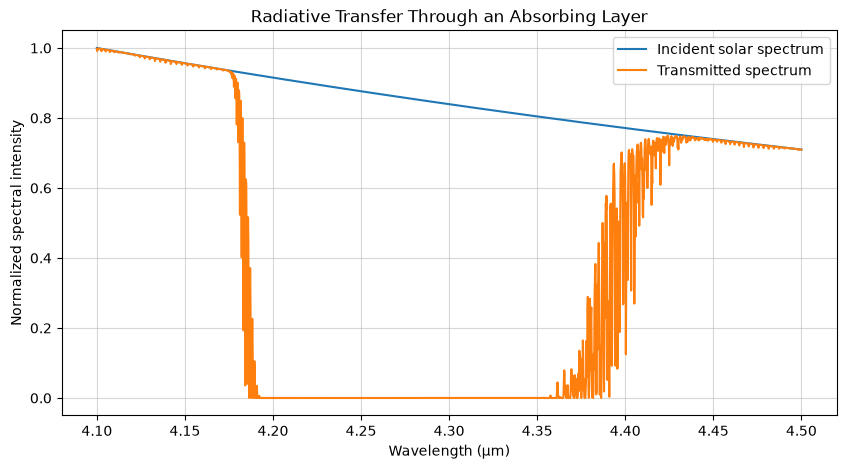

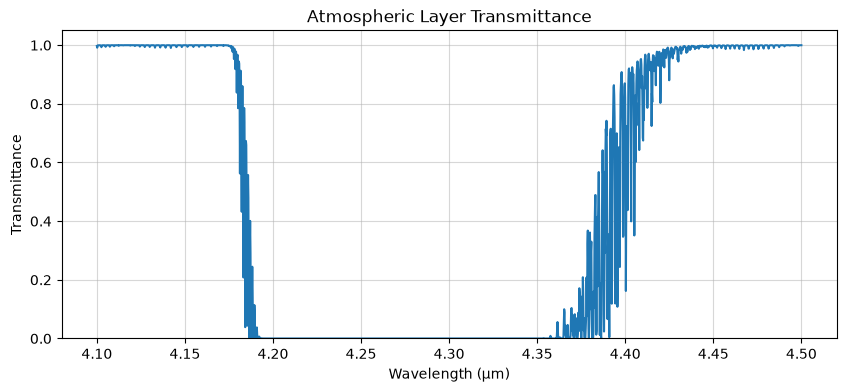

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hapi import db_begin, fetch, absorptionCoefficient_Voigt   # NEW: HITRAN API

# Physical constants (SI units)
h = 6.62607015e-34
c = 2.99792458e8
kB = 1.380649e-23

# Sun and atmospheric layer
T_sun = 5778                 # K
L_cm = 1e5                   # 1 km, expressed in cm

# Wavelength range around the CO2 4.3-micron band
wavelength_um = np.linspace(4.1, 4.5, 2000)
wavelength_m = wavelength_um * 1e-6

# Planck's law: solar blackbody spectral radiance
B_lambda = (2 * h * c**2 / wavelength_m**5 / np.expm1(h * c / (wavelength_m * kB * T_sun)))

# Normalize the incident spectrum for plotting
I0 = B_lambda / B_lambda.max()

# ---------------- NEW: absorption coefficient from HITRAN ----------------
T_gas = 288.0                # K  (sea level)
p_atm = 1.0                  # atm
x_CO2 = 4.2e-4               # CO2 mole fraction (~420 ppm)
n_total = 101325.0 * p_atm / (kB * T_gas) * 1e-6   # molecules/cm^3 (~2.5e19)
n_CO2 = x_CO2 * n_total                            # CO2 number density, molecules/cm^3

# Wavelength range -> wavenumber range (cm^-1), with a small margin
nu_min = 1e4 / wavelength_um.max() - 20     # ~2200 cm^-1
nu_max = 1e4 / wavelength_um.min() + 20     # ~2460 cm^-1

db_begin('hitran_data')                      # local folder where line lists are stored
fetch('CO2', 2, 1, nu_min, nu_max)           # (table name, molecule 2 = CO2, isotopologue 1, range)
# Note: only the main isotopologue (12C16O2) is fetched. Add 2, 3, ... for 13CO2 etc.

nu_hitran, sigma_hitran = absorptionCoefficient_Voigt(
    SourceTables='CO2',
    Environment={'T': T_gas, 'p': p_atm},
    Diluent={'air': 1 - x_CO2, 'self': x_CO2},
    WavenumberRange=(nu_min, nu_max),
    WavenumberStep=0.01,                     # cm^-1 (fine enough to resolve lines at 1 atm)
    HITRAN_units=True)                       # sigma in cm^2/molecule

# Put sigma on your wavelength grid (nu_hitran is ascending, so interp works directly)
sigma = np.interp(1e4 / wavelength_um, nu_hitran, sigma_hitran)   # cm^2/molecule

# Absorption coefficient alpha = n * sigma  [cm^-1]
alpha = n_CO2 * sigma
# -------------------------------------------------------------------------

# Beer-Lambert law
optical_depth = alpha * L_cm
transmittance = np.exp(-optical_depth)
I_transmitted = I0 * transmittance

# Plot spectra
plt.figure(figsize=(10, 5))
plt.plot(wavelength_um, I0, label="Incident solar spectrum")
plt.plot(wavelength_um, I_transmitted, label="Transmitted spectrum")
plt.xlabel("Wavelength (µm)")
plt.ylabel("Normalized spectral intensity")
plt.title("Radiative Transfer Through an Absorbing Layer")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

# Plot transmittance
plt.figure(figsize=(10, 4))
plt.plot(wavelength_um, transmittance)
plt.xlabel("Wavelength (µm)")
plt.ylabel("Transmittance")
plt.title("Atmospheric Layer Transmittance")
plt.ylim(0, 1.05)
plt.grid(alpha=0.5)
plt.show()